# Telecom Churn Risk Model — cost-aware, calibrated, explainable
Fictional Chennai operator · IBM Telco churn dataset (7,043 customers) · pandas + scikit-learn pipelines

**Flow:** audit & clean → leak-free pipeline → feature engineering + ablation → tune 3 models (stratified 5-fold CV) → compare → calibrate → cost-based threshold → lift → SHAP → segments → save.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, json
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             brier_score_loss, confusion_matrix)
import churn_utils as u
SEED = 42; np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Data audit and cleaning
Issues to handle: blank `TotalCharges`, inconsistent labels (`No internet service`, `No phone service`), ~1-in-4 churn imbalance, and leakage risk.

In [2]:
raw = pd.read_csv('telco.csv')
print(raw.shape); print('blank TotalCharges:', (raw.TotalCharges.str.strip()=='').sum(),
      '| their tenure values:', raw.loc[raw.TotalCharges.str.strip()=='','tenure'].unique())
print('label variants in MultipleLines:', raw.MultipleLines.unique(), '| OnlineSecurity:', raw.OnlineSecurity.unique())
df = u.clean_telco(raw)
print('\nchurn rate:', round(df.Churn.mean(),4), '| duplicates IDs:', df.customerID.duplicated().sum())
df.Churn.value_counts().rename({0:'stayed',1:'churned'})

(7043, 21)
blank TotalCharges: 11 | their tenure values: [0]
label variants in MultipleLines: <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str | OnlineSecurity: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

churn rate: 0.2654 | duplicates IDs: 0


Churn
stayed     5174
churned    1869
Name: count, dtype: int64

### Leakage controls
* `customerID` is dropped (identifier, no signal).
* Cleaning is **row-wise only** (no means/frequencies learned from the whole data set). Every learned step — imputation, scaling, one-hot categories — lives inside the `Pipeline`, so it is fitted on training folds only.
* Engineered features are **stateless** formulas of columns known at scoring time (no target-encoding, no group statistics).
* `TotalCharges` is cumulative billing and ~ `tenure × MonthlyCharges`; it is legitimate at scoring time for an active customer, but would leak if the snapshot was taken *after* churn. We assume scoring on active customers and note this as a deployment caveat.
* The 20% test set is touched exactly once, at the end.

In [3]:
X = df.drop(columns=['Churn','customerID']); y = df['Churn']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(X_tr.shape, X_te.shape, 'train churn %.3f | test churn %.3f' % (y_tr.mean(), y_te.mean()))

(5634, 19) (1409, 19) train churn 0.265 | test churn 0.265


## 2. Quick EDA

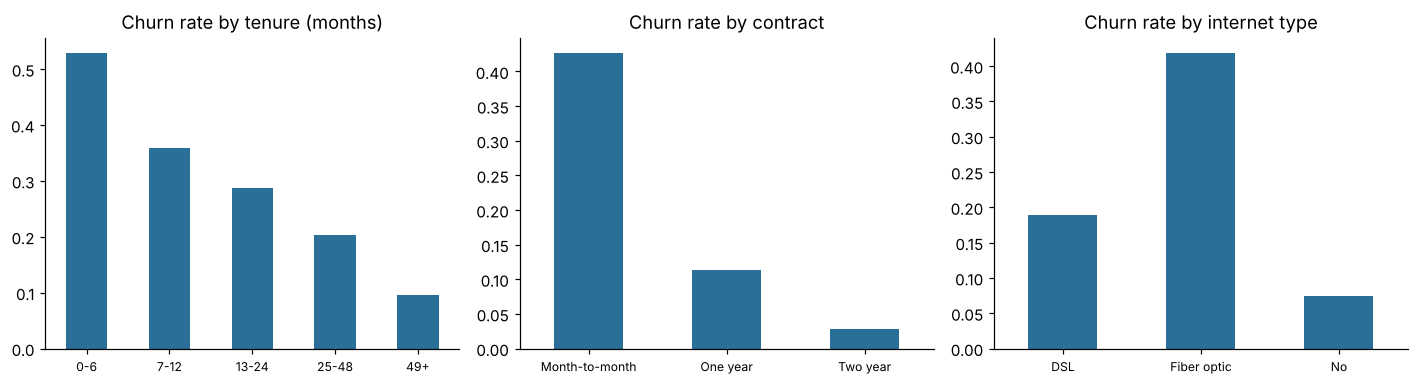

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
d = df.copy(); d['band'] = pd.cut(d.tenure,[-1,6,12,24,48,100],labels=['0-6','7-12','13-24','25-48','49+'])
d.groupby('band').Churn.mean().plot.bar(ax=ax[0], color='#2a6f97'); ax[0].set_title('Churn rate by tenure (months)')
d.groupby('Contract').Churn.mean().plot.bar(ax=ax[1], color='#2a6f97'); ax[1].set_title('Churn rate by contract')
d.groupby('InternetService').Churn.mean().plot.bar(ax=ax[2], color='#2a6f97'); ax[2].set_title('Churn rate by internet type')
for a in ax: a.set_xlabel(''); a.tick_params(axis='x', rotation=0, labelsize=8)
plt.tight_layout(); plt.savefig('eda_churn_rates.png'); plt.show()

## 3. Engineered features and ablation
15 features in 5 families (see `churn_utils.py`): tenure bands/new-customer flag; charge per tenure month, charge gap, high-charge flag; bundle counts (services, protection, streaming, internet); month-to-month & autopay; fiber-without-support & household size.

Ablation = 5-fold CV ROC AUC on the **training set** with the whole feature set, no engineered features, and each family removed in turn (logistic regression and gradient boosting).

In [5]:
def cv_auc(groups, model):
    pipe = Pipeline([('prep', u.make_preprocessor(groups, scale=True)), ('clf', model)])
    return cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring='roc_auc').mean()

lr0 = lambda: LogisticRegression(max_iter=2000, class_weight='balanced', C=0.3)
gb0 = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, class_weight='balanced', random_state=SEED)
allg = tuple(u.FEATURE_GROUPS)
rows = [('All engineered features', allg), ('No engineered features', ())]
rows += [(f'Drop "{g}" family', tuple(k for k in allg if k != g)) for g in allg]
abl = pd.DataFrame([{'setting': n, 'LogReg AUC': cv_auc(g, lr0()), 'GradBoost AUC': cv_auc(g, gb0())} for n, g in rows]).set_index('setting')
abl['LogReg Δ vs all'] = abl['LogReg AUC'] - abl.loc['All engineered features','LogReg AUC']
abl['GB Δ vs all'] = abl['GradBoost AUC'] - abl.loc['All engineered features','GradBoost AUC']
abl.round(4).to_csv('ablation_table.csv'); abl.round(4)

,LogReg AUC,GradBoost AUC,LogReg Δ vs all,GB Δ vs all
setting,,,,
All engineered features,0.8468,0.8462,0.0000,0.0000
No engineered features,0.8456,0.8472,-0.0012,0.0010
"Drop ""tenure"" family",0.8452,0.8465,-0.0016,0.0002
"Drop ""charges"" family",0.8475,0.8469,0.0006,0.0007
"Drop ""bundles"" family",0.8467,0.8470,-0.0001,0.0007
"Drop ""contract"" family",0.8468,0.8463,-0.0000,0.0000
"Drop ""risk"" family",0.8470,0.8458,0.0001,-0.0005


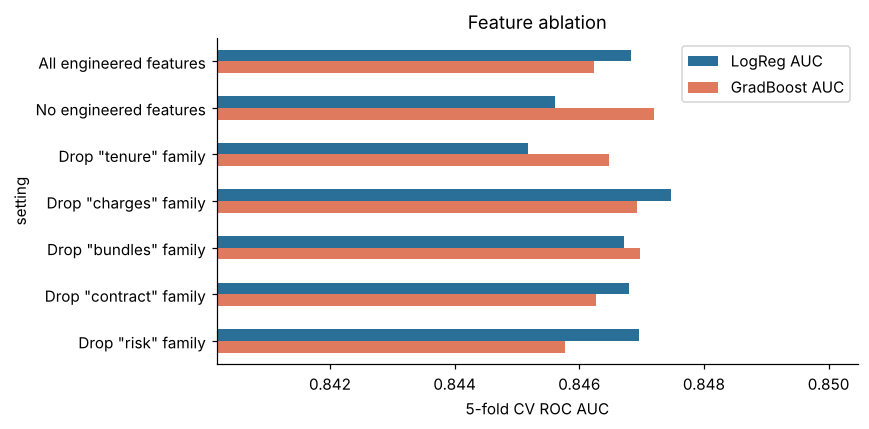

In [6]:
ax = abl.iloc[:, :2].plot.barh(figsize=(8, 4), color=['#2a6f97','#e07a5f']); ax.set_xlim(abl.iloc[:, :2].min().min()-0.005, abl.iloc[:, :2].max().max()+0.003)
ax.invert_yaxis(); ax.set_xlabel('5-fold CV ROC AUC'); ax.set_title('Feature ablation'); plt.tight_layout(); plt.savefig('ablation_chart.png'); plt.show()

## 4. Tune three models — stratified 5-fold CV
Imbalance is handled with class weights (`balanced`, `balanced_subsample`). Search metric: ROC AUC.

In [7]:
from scipy.stats import loguniform, randint, uniform
def prep(scale): return u.make_preprocessor(allg, scale=scale)
specs = {
 'Logistic Regression': (Pipeline([('prep', prep(True)), ('clf', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
                         {'clf__C': loguniform(1e-3, 10), 'clf__penalty': ['l2']}, 20),
 'Random Forest': (Pipeline([('prep', prep(False)), ('clf', RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=SEED))]),
                   {'clf__n_estimators': randint(200, 500), 'clf__max_depth': randint(4, 14),
                    'clf__min_samples_leaf': randint(5, 40), 'clf__max_features': ['sqrt', 0.3, 0.5]}, 12),
 'Gradient Boosting': (Pipeline([('prep', prep(False)), ('clf', HistGradientBoostingClassifier(class_weight='balanced', early_stopping=False, random_state=SEED))]),
                       {'clf__learning_rate': loguniform(0.01, 0.15), 'clf__max_iter': randint(80, 300),
                        'clf__max_depth': randint(2, 5), 'clf__min_samples_leaf': randint(20, 80),
                        'clf__l2_regularization': loguniform(1e-2, 10)}, 12),
}
searches = {}
for name, (pipe, grid, n) in specs.items():
    s = RandomizedSearchCV(pipe, grid, n_iter=n, scoring='roc_auc', cv=cv, random_state=SEED, n_jobs=1, refit=True).fit(X_tr, y_tr)
    searches[name] = s; print(f'{name:20s} CV AUC = {s.best_score_:.4f}  {s.best_params_}')

Logistic Regression  CV AUC = 0.8469  {'clf__C': np.float64(0.05342937261279776), 'clf__penalty': 'l2'}


Random Forest        CV AUC = 0.8483  {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 19, 'clf__n_estimators': 306}


Gradient Boosting    CV AUC = 0.8473  {'clf__l2_regularization': np.float64(6.708188643346286), 'clf__learning_rate': np.float64(0.045970407056545724), 'clf__max_depth': 3, 'clf__max_iter': 88, 'clf__min_samples_leaf': 45}


## 5. Compare models on the held-out test set
Precision/recall are shown at the default 0.5 cut-off on each model's own probabilities (class-weighted, hence recall-heavy); ROC AUC and PR AUC are threshold-free.

In [8]:
rows = []
for name, s in searches.items():
    p = s.predict_proba(X_te)[:, 1]; yh = (p >= 0.5).astype(int)
    rows.append({'Model': name, 'CV ROC AUC': s.best_score_, 'Test ROC AUC': roc_auc_score(y_te, p),
                 'Test PR AUC': average_precision_score(y_te, p),
                 'Precision@0.5': precision_score(y_te, yh), 'Recall@0.5': recall_score(y_te, yh)})
cmp = pd.DataFrame(rows).set_index('Model').round(4)
print('Baseline PR AUC (random) = churn rate = %.3f' % y_te.mean()); cmp

Baseline PR AUC (random) = churn rate = 0.265


,CV ROC AUC,Test ROC AUC,Test PR AUC,Precision@0.5,Recall@0.5
Model,,,,,
Logistic Regression,0.8469,0.8453,0.6530,0.5138,0.7968
Random Forest,0.8483,0.8466,0.6575,0.5372,0.7914
Gradient Boosting,0.8473,0.8460,0.6598,0.5100,0.8155


## 6. Calibrate probabilities and pick the decision threshold from a cost matrix
Costs: **missed churner (FN) = 5**, **wasted offer (FP) = 1**, correct calls = 0.
For a perfectly calibrated model the cost-minimising rule is *flag if p > 1/(1+5) = 0.167*. We (a) calibrate with 5-fold sigmoid calibration, (b) pick the threshold that minimises cost on **out-of-fold training predictions**, and (c) apply it once to the test set.

Selected model (best CV AUC): Random Forest


Brier raw 0.1576 -> calibrated 0.1354 | test ROC AUC raw 0.8466 -> calibrated 0.8469


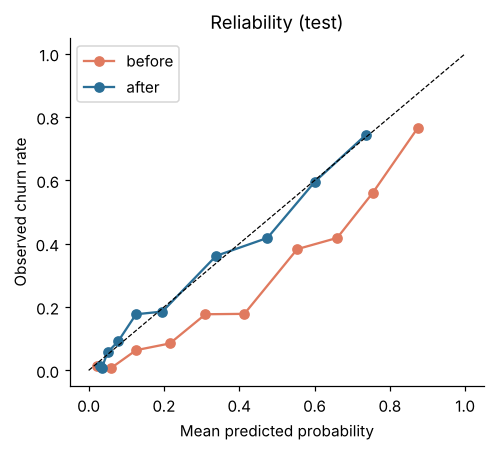

In [9]:
best_name = cmp['CV ROC AUC'].idxmax(); print('Selected model (best CV AUC):', best_name)
best_pipe = searches[best_name].best_estimator_
cal = CalibratedClassifierCV(best_pipe, method='sigmoid', cv=5)
oof_cal = cross_val_predict(cal, X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]     # out-of-fold, calibrated
oof_raw = cross_val_predict(best_pipe, X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]
cal.fit(X_tr, y_tr)
p_te_raw = best_pipe.predict_proba(X_te)[:, 1]; p_te = cal.predict_proba(X_te)[:, 1]
print('Brier raw %.4f -> calibrated %.4f | test ROC AUC raw %.4f -> calibrated %.4f' % (
      brier_score_loss(y_te, p_te_raw), brier_score_loss(y_te, p_te), roc_auc_score(y_te, p_te_raw), roc_auc_score(y_te, p_te)))

fig, ax = plt.subplots(figsize=(4.6, 4.2))
for p, lab, c in [(p_te_raw, 'before', '#e07a5f'), (p_te, 'after', '#2a6f97')]:
    fx, fy = calibration_curve(y_te, p, n_bins=10, strategy='quantile'); ax.plot(fy, fx, 'o-', label=lab, color=c)
ax.plot([0,1],[0,1],'k--', lw=.8); ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed churn rate')
ax.set_title('Reliability (test)'); ax.legend(); plt.tight_layout(); plt.savefig('calibration_curve.png'); plt.show()

Cost-optimal threshold (OOF): 0.165 | theory 1/6 = 0.167


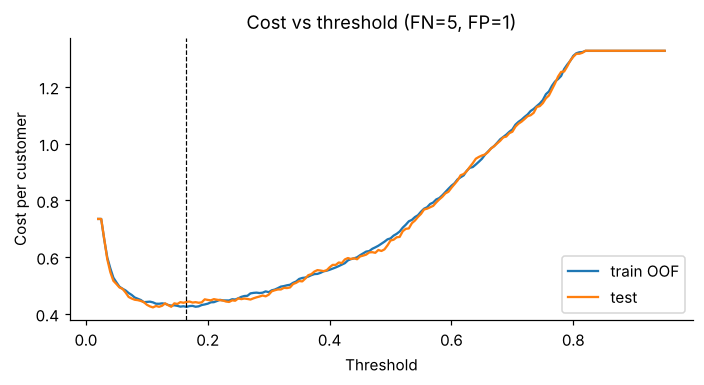

Threshold                        0.165000
Precision                        0.472754
Recall                           0.858289
TP                             321.000000
FP                             358.000000
FN                              53.000000
TN                             677.000000
Cost (model)                   623.000000
Cost (offer nobody)           1870.000000
Cost (offer everybody)        1035.000000
Cost (random, same volume)    1468.200000
Saving vs best naive %          39.800000
dtype: float64

In [10]:
COST_FN, COST_FP = 5, 1
def total_cost(y, p, t):
    yh = (p >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh).ravel(); return COST_FN*fn + COST_FP*fp
ts = np.linspace(0.02, 0.95, 187)
c_oof = np.array([total_cost(y_tr, oof_cal, t) for t in ts]); thr = float(ts[c_oof.argmin()])
print('Cost-optimal threshold (OOF): %.3f | theory 1/6 = %.3f' % (thr, 1/6))
c_te = np.array([total_cost(y_te, p_te, t) for t in ts])
plt.figure(figsize=(6.5, 3.6)); plt.plot(ts, c_oof/len(y_tr), label='train OOF'); plt.plot(ts, c_te/len(y_te), label='test')
plt.axvline(thr, color='k', ls='--', lw=.8); plt.xlabel('Threshold'); plt.ylabel('Cost per customer'); plt.title('Cost vs threshold (FN=5, FP=1)')
plt.legend(); plt.tight_layout(); plt.savefig('cost_curve.png'); plt.show()

yh = (p_te >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_te, yh).ravel()
cost_model = COST_FN*fn + COST_FP*fp
cost_none  = COST_FN*y_te.sum()                      # contact nobody
cost_all   = COST_FP*(y_te==0).sum()                 # offer to everyone
rng = np.random.default_rng(SEED); k = yh.sum()      # random targeting of the same number of customers
cost_rand = np.mean([ (lambda m: COST_FN*(y_te.values[~m].sum()) + COST_FP*((y_te.values[m]==0).sum()))(np.isin(np.arange(len(y_te)), rng.choice(len(y_te), k, replace=False))) for _ in range(500)])
res = pd.Series({'Threshold': thr, 'Precision': precision_score(y_te, yh), 'Recall': recall_score(y_te, yh),
                 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn, 'Cost (model)': cost_model, 'Cost (offer nobody)': cost_none,
                 'Cost (offer everybody)': cost_all, 'Cost (random, same volume)': round(cost_rand,1),
                 'Saving vs best naive %': round(100*(1-cost_model/min(cost_none, cost_all)),1)})
res

## 7. Lift over random targeting

,customers,churners,mean_prob,churn_rate,lift,cum_capture,cum_lift
decile,,,,,,,
1,141,105,0.737,0.745,2.805,0.281,2.805
2,141,84,0.601,0.596,2.244,0.505,2.525
3,141,59,0.475,0.418,1.576,0.663,2.209
4,141,51,0.339,0.362,1.363,0.799,1.997
5,141,26,0.196,0.184,0.695,0.869,1.737
6,140,25,0.126,0.179,0.673,0.936,1.560
7,141,13,0.079,0.092,0.347,0.971,1.387
8,141,8,0.050,0.057,0.214,0.992,1.240
9,141,1,0.035,0.007,0.027,0.995,1.105


Top-2 deciles: churn rate 67.0% vs base 26.5% -> lift 2.52x, capture 50.5% of all churners (random would capture 20%)


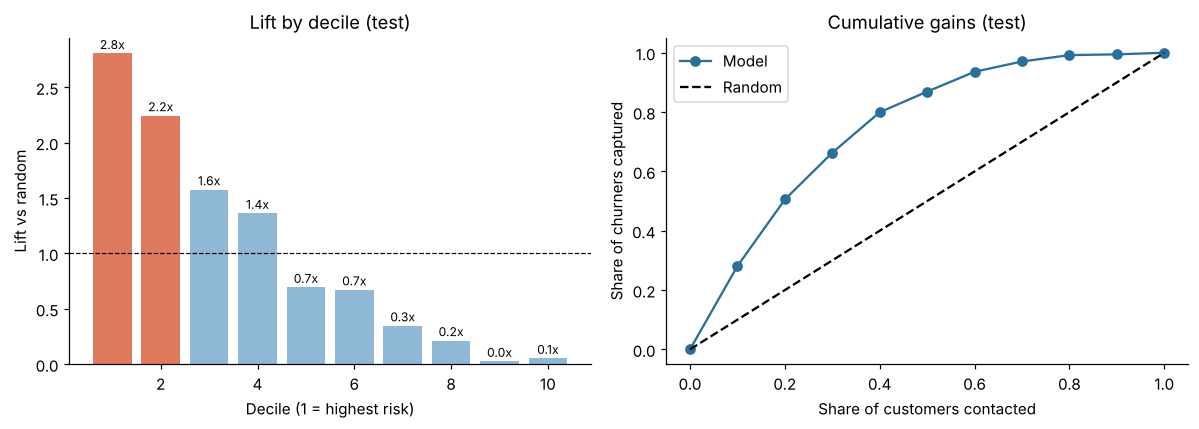

In [11]:
def decile_table(y, p):
    d = pd.DataFrame({'y': np.asarray(y), 'p': p}).sort_values('p', ascending=False).reset_index(drop=True)
    d['decile'] = pd.qcut(d.index, 10, labels=range(1, 11))
    g = d.groupby('decile', observed=True).agg(customers=('y','size'), churners=('y','sum'), mean_prob=('p','mean'))
    g['churn_rate'] = g.churners/g.customers; g['lift'] = g.churn_rate/d.y.mean()
    g['cum_capture'] = g.churners.cumsum()/d.y.sum(); g['cum_lift'] = g.cum_capture/(g.customers.cumsum()/len(d)); return g
lt = decile_table(y_te, p_te); lt.round(3).to_csv('decile_lift_table.csv'); display(lt.round(3))
top2 = lt.loc[[1,2]]
print('Top-2 deciles: churn rate %.1f%% vs base %.1f%% -> lift %.2fx, capture %.1f%% of all churners (random would capture 20%%)' % (
      100*top2.churners.sum()/top2.customers.sum(), 100*y_te.mean(), (top2.churners.sum()/top2.customers.sum())/y_te.mean(), 100*lt.loc[2,'cum_capture']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(lt.index.astype(int), lt.lift, color=['#e07a5f' if i<=2 else '#8fb8d6' for i in lt.index.astype(int)]); ax[0].axhline(1, color='k', ls='--', lw=.8)
ax[0].set_xlabel('Decile (1 = highest risk)'); ax[0].set_ylabel('Lift vs random'); ax[0].set_title('Lift by decile (test)')
for i, v in zip(lt.index.astype(int), lt.lift): ax[0].text(i, v+.04, f'{v:.1f}x', ha='center', fontsize=8)
xs = np.r_[0, np.arange(1, 11)/10]; ax[1].plot(xs, np.r_[0, lt.cum_capture], 'o-', color='#2a6f97', label='Model'); ax[1].plot([0,1],[0,1],'k--', label='Random')
ax[1].set_xlabel('Share of customers contacted'); ax[1].set_ylabel('Share of churners captured'); ax[1].set_title('Cumulative gains (test)'); ax[1].legend()
plt.tight_layout(); plt.savefig('lift_chart.png', dpi=160); plt.show()

## 8. SHAP explanations (stretch)
Global importance and individual customer explanations from the tuned model (pre-calibration; calibration is monotone so the ranking of drivers is unchanged).

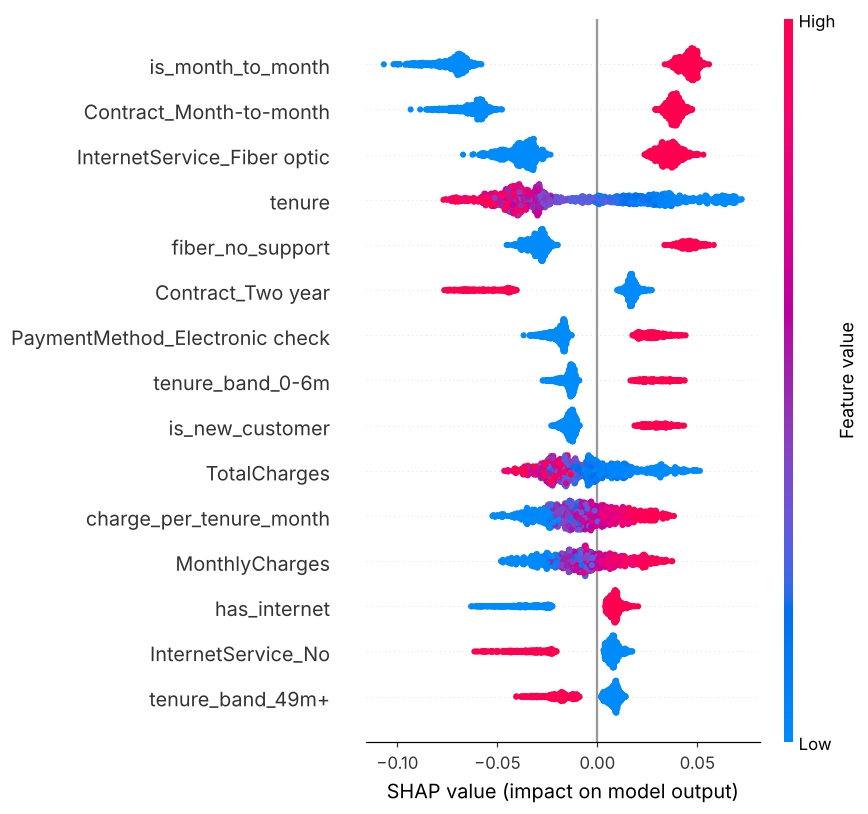

is_month_to_month                 0.0580
Contract_Month-to-month           0.0494
InternetService_Fiber optic       0.0374
tenure                            0.0359
fiber_no_support                  0.0342
Contract_Two year                 0.0262
PaymentMethod_Electronic check    0.0222
tenure_band_0-6m                  0.0174
is_new_customer                   0.0173
TotalCharges                      0.0170
charge_per_tenure_month           0.0161
MonthlyCharges                    0.0159
dtype: float64

In [12]:
import shap
prep_f = best_pipe.named_steps['prep']; clf = best_pipe.named_steps['clf']
Xt_te = prep_f.transform(X_te); Xt_tr = prep_f.transform(X_tr)
if best_name == 'Logistic Regression':
    expl = shap.LinearExplainer(clf, Xt_tr); sv = expl.shap_values(Xt_te)
else:
    expl = shap.TreeExplainer(clf); sv = expl.shap_values(Xt_te)
    if isinstance(sv, list): sv = sv[1]
    if getattr(sv, 'ndim', 2) == 3: sv = sv[:, :, 1]
sv = np.asarray(sv); feat = list(Xt_te.columns)
imp = pd.Series(np.abs(sv).mean(0), index=feat).sort_values(ascending=False)
plt.figure(); shap.summary_plot(sv, Xt_te, max_display=15, show=False); plt.tight_layout(); plt.savefig('shap_summary.png', dpi=140, bbox_inches='tight'); plt.show()
imp.head(12).round(4)


Highest risk: calibrated churn prob = 0.82
tenure                         0.046
is_month_to_month              0.044
fiber_no_support               0.043
Contract_Month-to-month        0.036
InternetService_Fiber optic    0.035

Mid risk: calibrated churn prob = 0.15
tenure                        -0.049
InternetService_Fiber optic   -0.046
is_month_to_month              0.043
fiber_no_support              -0.036
Contract_Month-to-month        0.035

Lowest risk: calibrated churn prob = 0.03
is_month_to_month             -0.068
Contract_Month-to-month       -0.059
Contract_Two year             -0.045
tenure                        -0.041
InternetService_Fiber optic   -0.032


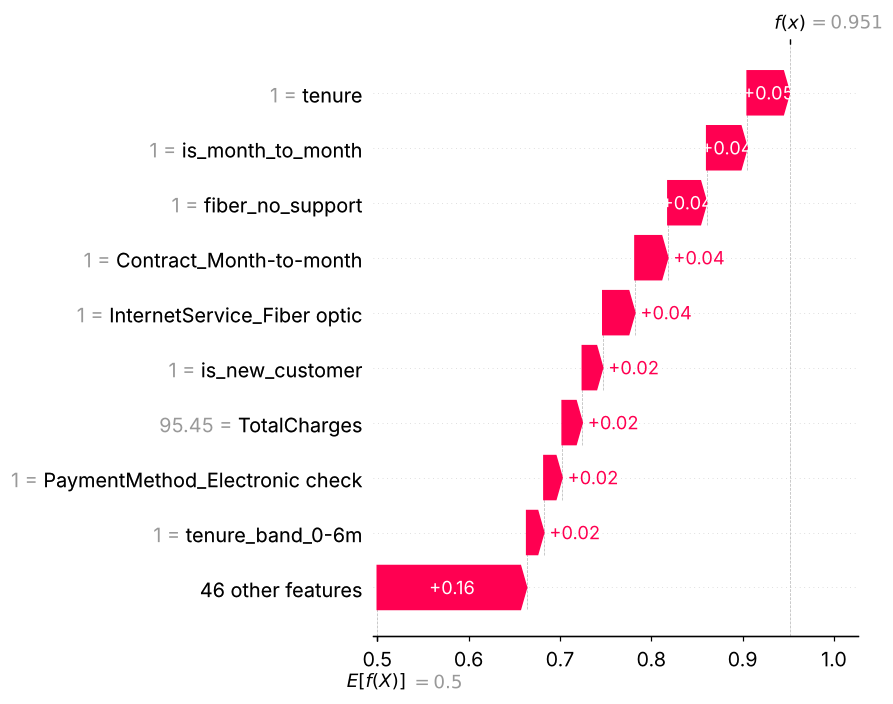

In [13]:
# individual customers: highest-risk, a mid-risk and a low-risk customer
order = np.argsort(-p_te); picks = {'Highest risk': order[0], 'Mid risk': order[len(order)//2], 'Lowest risk': order[-1]}
def explain(i, k=5):
    s = pd.Series(sv[i], index=feat); top = s.reindex(s.abs().sort_values(ascending=False).index)[:k]
    return top.round(3)
for lab, i in picks.items():
    print(f'\n{lab}: calibrated churn prob = {p_te[i]:.2f}'); print(explain(i).to_string())
i = picks['Highest risk']
shap.plots.waterfall(shap.Explanation(sv[i], expl.expected_value if np.isscalar(expl.expected_value) else float(np.ravel(expl.expected_value)[-1]),
                     Xt_te.iloc[i].values, feature_names=feat), max_display=10, show=False)
plt.tight_layout(); plt.savefig('shap_customer_waterfall.png', dpi=140, bbox_inches='tight'); plt.show()

## 9. Three retention segments (stretch)
Rule-based segments on the test customers, tied to the main SHAP drivers (contract, tenure, internet/support) and sized with the calibrated probabilities.

In [14]:
te = X_te.copy(); te['churn'] = y_te.values; te['p'] = p_te
te = u.FeatureEngineer().transform(te)
def seg(r):
    if r.p < thr: return 'D. Low risk – keep warm'
    if r.is_month_to_month == 1 and r.tenure <= 12: return 'A. New month-to-month'
    if r.InternetService == 'Fiber optic' and r.TechSupport == 'No' and r.OnlineSecurity == 'No': return 'B. Unsupported fiber users'
    return 'C. Price-sensitive / at-risk other'
te['segment'] = te.apply(seg, axis=1)
S = te.groupby('segment').agg(customers=('p','size'), actual_churn=('churn','mean'), avg_pred=('p','mean'),
        avg_monthly=('MonthlyCharges','mean'), avg_tenure=('tenure','mean'), share_mtm=('is_month_to_month','mean')).round(3)
S['share_of_churners'] = (te.groupby('segment').churn.sum()/te.churn.sum()).round(3); S.to_csv('retention_segments.csv'); S

,customers,actual_churn,avg_pred,avg_monthly,avg_tenure,share_mtm,share_of_churners
segment,,,,,,,
A. New month-to-month,350,0.569,0.565,62.509,3.937,1.000,0.532
B. Unsupported fiber users,169,0.462,0.473,89.407,33.047,0.876,0.209
C. Price-sensitive / at-risk other,160,0.275,0.307,82.208,32.756,0.819,0.118
D. Low risk – keep warm,730,0.073,0.067,55.014,44.884,0.197,0.142


## 10. Final check and save
Targets: test ROC AUC ≥ 0.84 and clear top-2-decile lift.

In [15]:
final_auc = roc_auc_score(y_te, p_te); lift2 = (top2.churners.sum()/top2.customers.sum())/y_te.mean()
print(f'Final test ROC AUC = {final_auc:.4f}  (target 0.84)  ->', 'PASS' if final_auc >= 0.84 else 'BELOW TARGET')
print(f'Top-2-decile lift  = {lift2:.2f}x  (random = 1.00x)')
joblib.dump({'model': cal, 'threshold': thr, 'costs': {'missed_churner': COST_FN, 'wasted_offer': COST_FP},
             'model_name': best_name, 'columns': list(X.columns)}, 'churn_model.joblib')
cmp.to_csv('model_comparison.csv')
json.dump({'model': best_name, 'threshold': thr, 'test_auc': final_auc, 'test_pr_auc': float(average_precision_score(y_te, p_te)),
           'lift_top2': lift2, 'capture_top2': float(lt.loc[2,'cum_capture']), 'result': {k: float(v) for k, v in res.items()},
           'top_shap': {k: float(v) for k, v in imp.head(10).items()}}, open('summary_metrics.json','w'), indent=2)
# reload test
bundle = joblib.load('churn_model.joblib'); chk = bundle['model'].predict_proba(X_te)[:, 1]
print('Reloaded model reproduces test predictions:', np.allclose(chk, p_te))

Final test ROC AUC = 0.8469  (target 0.84)  -> PASS
Top-2-decile lift  = 2.52x  (random = 1.00x)


Reloaded model reproduces test predictions: True
